# 1. Upload the Dataset "model_dataset.xlsx"


In [1]:
from google.colab import files

uploaded = files.upload()

Saving model_dataset.xlsx to model_dataset.xlsx


# 2. Import Required Packages

In [2]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 5553

print("Packages loaded successfully")

Packages loaded successfully


# 3. Load the Dataset Uploaded

In [3]:
file_path = "/content/model_dataset.xlsx"

model_data = pd.read_excel(
    file_path,
    sheet_name="Model_Data"
)

print("Dataset shape:", model_data.shape)
display(model_data.head())

Dataset shape: (49, 53)


,site_id,survey_batch_id,source_location_id,location_id,road_no,slk_km,road_name,survey_location_name,latitude,longitude,...,commercial_buildings,residential_buildings,industrial_buildings,parking_areas,fencing_barriers,railway_station,bus_stops,overpass_bridge,park_bushland_reserve,shared_pedestrian_and_cycle_path
0,250303-01,250303,M074-52.8,M074-52.8,M074,52.80,Melville Mandurah Hwy,Melville Mandurah Hwy Mandurah,-32.866282,115.705163,...,0,0,0,0,True,False,False,False,True,False
1,250303-02,250303,H009-155.15,H009-155.15,H009,155.15,South Western Hwy,South Western Hwy Bunbury,-33.359642,115.678041,...,0,0,3,1,True,False,False,False,True,True
2,250303-03,250303,H045-36.1,H045-36.1,H045,36.10,Coalfields Hwy,Coalfields Hwy Collie,-33.360624,116.154738,...,6,0,0,3,True,True,False,False,True,True
3,250303-04,250303,H009-278.3,H009-278.3,H009,278.30,South Western Hwy,South Western Hwy Manjimup,-34.238746,116.149491,...,1,7,0,2,True,False,False,False,False,False
4,250303-05,250303,H009-57.9,H009-57.9,H009,57.90,South Western Hwy,South Western Hwy Pinjarra,-32.628918,115.874612,...,8,2,0,4,True,False,False,False,True,False


# 4. Check the Targets and Identifiers

In [4]:
target_columns = [
    "obs_peak_cross_ped_per_h",
    "obs_peak_along_ped_per_h"
]

print("Number of rows:", len(model_data))
print("Unique sites:", model_data["site_id"].nunique())
print("Unique locations:", model_data["location_id"].nunique())
print("Unique roads:", model_data["road_no"].nunique())

print("\nMissing target values:")
display(model_data[target_columns].isna().sum())

print("\nTarget summaries:")
display(model_data[target_columns].describe())

Number of rows: 49
Unique sites: 49
Unique locations: 49
Unique roads: 28

Missing target values:


,0
obs_peak_cross_ped_per_h,0
obs_peak_along_ped_per_h,0



Target summaries:


,obs_peak_cross_ped_per_h,obs_peak_along_ped_per_h
count,49.000000,49.000000
mean,25.387755,39.870748
std,38.810696,70.525666
min,0.000000,0.666667
25%,3.000000,8.333333
50%,7.333333,13.000000
75%,32.333333,35.333333
max,192.333333,349.666667


# 5. Preparing the Features for Modelling

In [5]:
model_data = model_data.copy()

# Combine rare land-use categories
model_data["abs_mb_category_simple"] = np.where(
    model_data["abs_mb_category_2021"].isin(
        ["Residential", "Commercial"]
    ),
    model_data["abs_mb_category_2021"],
    "Other"
)

numeric_features = [
    "commercial_buildings",
    "parking_areas",
    "pedestrian_crossings",
    "overture_food_drink_count_500m",
    "overture_grocery_convenience_pharmacy_count_500m",
    "overture_other_shopping_count_500m",
    "pta_active_stops_within_500m",
    "ms_building_count_500m",
    "abs_mb_persons_per_sqkm_2021"
]

binary_features = [
    "footpath_both_sides",
    "overture_shopping_mall_present_500m",
    "shared_pedestrian_and_cycle_path"
]

categorical_features = [
    "abs_mb_category_simple"
]

feature_columns = (
    numeric_features
    + binary_features
    + categorical_features
)

X = model_data[feature_columns].copy()

for column in binary_features:
    X[column] = X[column].astype(int)

groups = model_data["road_no"].astype(str)
site_ids = model_data["site_id"].astype(str)

print("Observations:", len(X))
print("Predictor columns:", len(feature_columns))
print("Road groups:", groups.nunique())

display(X.head())

Observations: 49
Predictor columns: 13
Road groups: 28


,commercial_buildings,parking_areas,pedestrian_crossings,overture_food_drink_count_500m,overture_grocery_convenience_pharmacy_count_500m,overture_other_shopping_count_500m,pta_active_stops_within_500m,ms_building_count_500m,abs_mb_persons_per_sqkm_2021,footpath_both_sides,overture_shopping_mall_present_500m,shared_pedestrian_and_cycle_path,abs_mb_category_simple
0,0,0,0,0,0,0,0,12,9.317787,0,0,0,Residential
1,0,1,0,3,0,19,0,175,0.000000,1,0,1,Other
2,6,3,1,19,8,35,4,370,0.000000,1,1,1,Other
3,1,2,0,14,13,20,11,392,0.000000,0,0,0,Commercial
4,8,4,1,20,7,19,13,329,0.000000,1,1,0,Commercial


# 6 Creating the Preprocessing Pipeline

In [6]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

binary_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "binary",
            binary_pipeline,
            binary_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created")

Preprocessing pipeline created


# 7. Define Random Forest & Tunning Grid

In [7]:
random_forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

random_forest_parameters = {
    "model__max_depth": [
        3,
        None
    ],
    "model__min_samples_leaf": [
        2,
        4
    ],
    "model__max_features": [
        0.5,
        1.0
    ]
}

print(
    "Parameter combinations:",
    np.prod([
        len(values)
        for values in random_forest_parameters.values()
    ])
)

Parameter combinations: 8


# 8. Defining the Evaluation Functions

In [8]:
def calculate_regression_metrics(actual, predicted):
    predicted = np.maximum(predicted, 0)

    return {
        "MAE": mean_absolute_error(
            actual,
            predicted
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        ),
        "Median_AE": median_absolute_error(
            actual,
            predicted
        ),
        "R2": r2_score(
            actual,
            predicted
        )
    }


def evaluate_random_forest(
    X,
    y,
    groups,
    site_ids,
    target_name,
    outer_splits=5
):
    X = X.reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)
    groups = pd.Series(groups).reset_index(drop=True)
    site_ids = pd.Series(site_ids).reset_index(drop=True)

    outer_cv = GroupKFold(
        n_splits=outer_splits
    )

    out_of_fold_predictions = np.full(
        len(y),
        np.nan
    )

    fold_results = []

    for fold_number, (train_index, test_index) in enumerate(
        outer_cv.split(X, y, groups),
        start=1
    ):
        print(
            f"{target_name}: processing fold "
            f"{fold_number}/{outer_splits}"
        )

        X_train = X.iloc[train_index]
        X_test = X.iloc[test_index]

        y_train = y.iloc[train_index]
        y_test = y.iloc[test_index]

        training_groups = groups.iloc[train_index]

        inner_splits = min(
            4,
            training_groups.nunique()
        )

        inner_cv = GroupKFold(
            n_splits=inner_splits
        )

        search = GridSearchCV(
            estimator=clone(
                random_forest_pipeline
            ),
            param_grid=random_forest_parameters,
            scoring="neg_mean_absolute_error",
            cv=inner_cv,
            n_jobs=-1,
            refit=True
        )

        search.fit(
            X_train,
            y_train,
            groups=training_groups
        )

        fold_predictions = search.predict(
            X_test
        )

        fold_predictions = np.maximum(
            fold_predictions,
            0
        )

        out_of_fold_predictions[
            test_index
        ] = fold_predictions

        fold_metrics = calculate_regression_metrics(
            y_test,
            fold_predictions
        )

        fold_results.append({
            "fold": fold_number,
            "training_rows": len(train_index),
            "validation_rows": len(test_index),
            "validation_roads": ", ".join(
                sorted(
                    groups.iloc[
                        test_index
                    ].unique()
                )
            ),
            "MAE": fold_metrics["MAE"],
            "RMSE": fold_metrics["RMSE"],
            "R2": fold_metrics["R2"],
            "best_parameters": str(
                search.best_params_
            )
        })

    overall_metrics = calculate_regression_metrics(
        y,
        out_of_fold_predictions
    )

    metrics_table = pd.DataFrame([
        {
            "Target": target_name,
            **overall_metrics
        }
    ])

    predictions_table = pd.DataFrame({
        "site_id": site_ids,
        "road_no": groups,
        "actual": y,
        "predicted": out_of_fold_predictions
    })

    predictions_table["residual"] = (
        predictions_table["actual"]
        - predictions_table["predicted"]
    )

    predictions_table["absolute_error"] = abs(
        predictions_table["residual"]
    )

    fold_results_table = pd.DataFrame(
        fold_results
    )

    return (
        metrics_table,
        predictions_table,
        fold_results_table
    )

# 9. Evaluate the Cross-Road Random Forest

In [9]:
(
    cross_metrics,
    cross_predictions,
    cross_fold_results
) = evaluate_random_forest(
    X=X,
    y=model_data[
        "obs_peak_cross_ped_per_h"
    ],
    groups=groups,
    site_ids=site_ids,
    target_name="Cross-road pedestrian flow"
)

print("Cross-road overall results:")
display(cross_metrics)

print("Cross-road fold results:")
display(cross_fold_results)

Cross-road pedestrian flow: processing fold 1/5
Cross-road pedestrian flow: processing fold 2/5
Cross-road pedestrian flow: processing fold 3/5
Cross-road pedestrian flow: processing fold 4/5
Cross-road pedestrian flow: processing fold 5/5
Cross-road overall results:


,Target,MAE,RMSE,Median_AE,R2
0,Cross-road pedestrian flow,19.702214,30.722929,10.68339,0.360299


Cross-road fold results:


,fold,training_rows,validation_rows,validation_roads,MAE,RMSE,R2,best_parameters
0,1,39,10,H009,22.107617,26.893585,0.506352,"{'model__max_depth': 3, 'model__max_features':..."
1,2,39,10,"H008, H042, H053, M028, M031, M074",14.505997,19.800168,-3.523615,"{'model__max_depth': None, 'model__max_feature..."
2,3,39,10,"H006, H007, H043, H046, M002, M032, M042",30.364968,48.260511,0.291433,"{'model__max_depth': 3, 'model__max_features':..."
3,4,39,10,"H004, H005, H010, H045, H049, M023, M045",10.671096,14.280802,-0.256063,"{'model__max_depth': None, 'model__max_feature..."
4,5,40,9,"H001, H011, H044, H047, H051, M026, M041",20.990190,32.943930,-0.057466,"{'model__max_depth': None, 'model__max_feature..."


# 10. Evaluate the Along Road Random Forest

In [10]:
(
    along_metrics,
    along_predictions,
    along_fold_results
) = evaluate_random_forest(
    X=X,
    y=model_data[
        "obs_peak_along_ped_per_h"
    ],
    groups=groups,
    site_ids=site_ids,
    target_name="Along-road pedestrian flow"
)

print("Along-road overall results:")
display(along_metrics)

print("Along-road fold results:")
display(along_fold_results)

Along-road pedestrian flow: processing fold 1/5
Along-road pedestrian flow: processing fold 2/5
Along-road pedestrian flow: processing fold 3/5
Along-road pedestrian flow: processing fold 4/5
Along-road pedestrian flow: processing fold 5/5
Along-road overall results:


,Target,MAE,RMSE,Median_AE,R2
0,Along-road pedestrian flow,30.262124,56.341556,13.979624,0.348494


Along-road fold results:


,fold,training_rows,validation_rows,validation_roads,MAE,RMSE,R2,best_parameters
0,1,39,10,H009,54.230269,87.857891,0.234946,"{'model__max_depth': None, 'model__max_feature..."
1,2,39,10,"H008, H042, H053, M028, M031, M074",17.727915,24.803676,-3.398600,"{'model__max_depth': None, 'model__max_feature..."
2,3,39,10,"H006, H007, H043, H046, M002, M032, M042",35.885111,69.816245,0.452613,"{'model__max_depth': 3, 'model__max_features':..."
3,4,39,10,"H004, H005, H010, H045, H049, M023, M045",14.333810,16.654340,0.640053,"{'model__max_depth': 3, 'model__max_features':..."
4,5,40,9,"H001, H011, H044, H047, H051, M026, M041",29.008117,47.941066,-0.441856,"{'model__max_depth': None, 'model__max_feature..."


# 11. Plot the Predictions

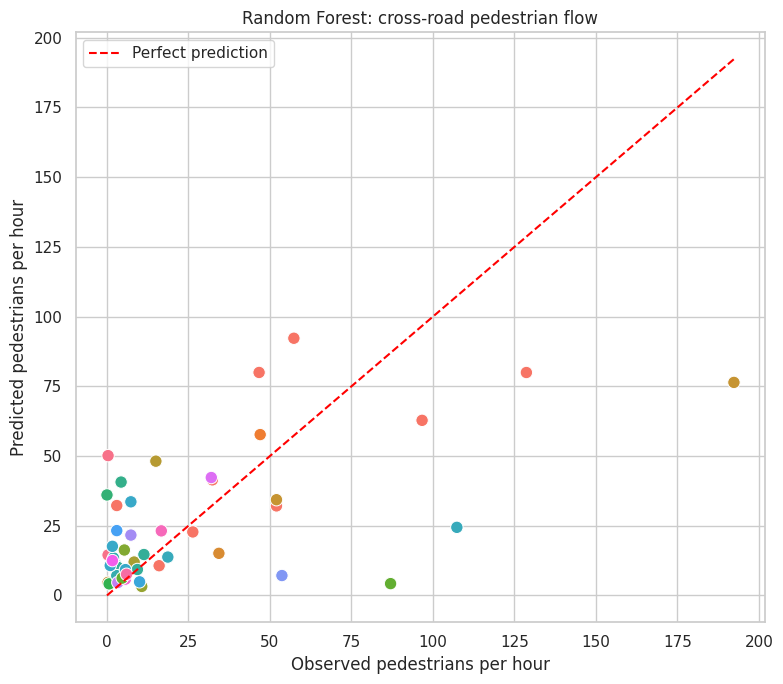

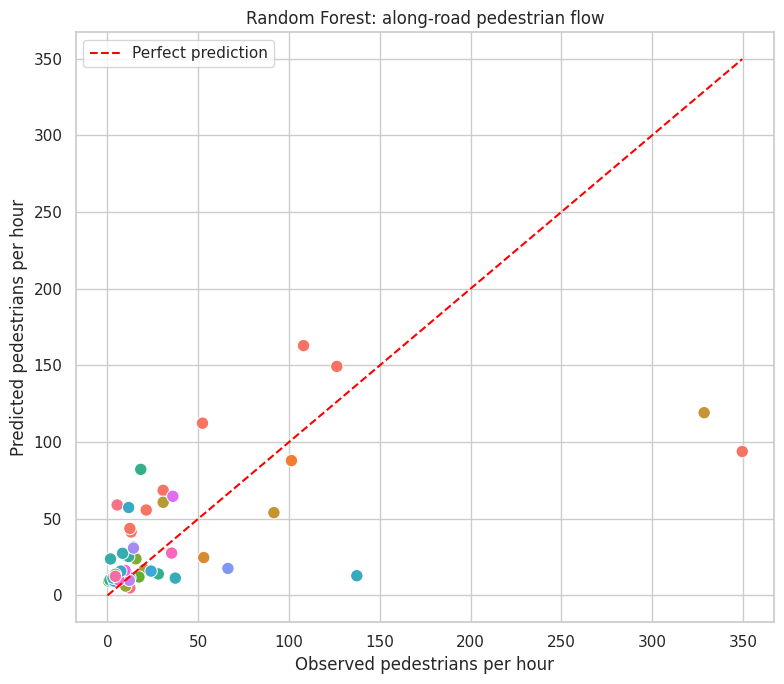

In [11]:
def plot_predictions(
    predictions,
    title
):
    maximum_value = max(
        predictions["actual"].max(),
        predictions["predicted"].max()
    )

    plt.figure(figsize=(8, 7))

    sns.scatterplot(
        data=predictions,
        x="actual",
        y="predicted",
        hue="road_no",
        legend=False,
        s=80
    )

    plt.plot(
        [0, maximum_value],
        [0, maximum_value],
        linestyle="--",
        color="red",
        label="Perfect prediction"
    )

    plt.xlabel(
        "Observed pedestrians per hour"
    )

    plt.ylabel(
        "Predicted pedestrians per hour"
    )

    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_predictions(
    cross_predictions,
    "Random Forest: cross-road pedestrian flow"
)

plot_predictions(
    along_predictions,
    "Random Forest: along-road pedestrian flow"
)

# 12. Display the Largest Prediction Errors

In [12]:
print("Largest cross-road prediction errors:")

display(
    cross_predictions.sort_values(
        "absolute_error",
        ascending=False
    ).head(10)
)

print("Largest along-road prediction errors:")

display(
    along_predictions.sort_values(
        "absolute_error",
        ascending=False
    ).head(10)
)

Largest cross-road prediction errors:


,site_id,road_no,actual,predicted,residual,absolute_error
10,250303-11,H043,192.333333,76.398000,115.935334,115.935334
29,260335-33,H001,107.333333,24.422423,82.910911,82.910911
20,250341-04,H006,87.000000,4.235803,82.764197,82.764197
14,250303-15,M074,0.333333,50.141901,-49.808568,49.808568
31,260335-35,H009,128.666667,79.950582,48.716084,48.716084
36,260335-40,H007,53.666667,7.131813,46.534854,46.534854
34,260335-38,H044,4.333333,40.659221,-36.325888,36.325888
22,250341-06,H051,0.000000,36.035798,-36.035798,36.035798
4,250303-05,H009,57.333333,92.238280,-34.904946,34.904946
9,250303-10,H009,96.666667,62.797666,33.869000,33.869000


Largest along-road prediction errors:


,site_id,road_no,actual,predicted,residual,absolute_error
9,250303-10,H009,349.666667,93.859870,255.806796,255.806796
10,250303-11,H043,328.666667,119.134767,209.531899,209.531899
29,260335-33,H001,137.333333,12.856937,124.476396,124.476396
34,260335-38,H044,18.333333,82.194735,-63.861402,63.861402
6,250303-07,H009,52.333333,112.319913,-59.986579,59.986579
4,250303-05,H009,108.000000,162.892401,-54.892401,54.892401
14,250303-15,M074,5.333333,58.984940,-53.651607,53.651607
36,260335-40,H007,66.333333,17.633309,48.700024,48.700024
43,260335-47,M031,11.666667,57.336571,-45.669905,45.669905
13,250303-14,H009,30.666667,68.519270,-37.852603,37.852603


# 13. Sensitivity Analysis
This removes the two sites with corrected target values.

In [13]:
corrected_target_sites = [
    "250341-04",
    "260335-38"
]

sensitivity_mask = ~model_data[
    "site_id"
].isin(corrected_target_sites)

X_sensitivity = X.loc[
    sensitivity_mask
].reset_index(drop=True)

sensitivity_data = model_data.loc[
    sensitivity_mask
].reset_index(drop=True)

groups_sensitivity = sensitivity_data[
    "road_no"
].astype(str)

site_ids_sensitivity = sensitivity_data[
    "site_id"
].astype(str)

print(
    "Sensitivity dataset rows:",
    len(sensitivity_data)
)

cross_sensitivity_metrics, _, _ = (
    evaluate_random_forest(
        X=X_sensitivity,
        y=sensitivity_data[
            "obs_peak_cross_ped_per_h"
        ],
        groups=groups_sensitivity,
        site_ids=site_ids_sensitivity,
        target_name=(
            "Cross-road sensitivity"
        )
    )
)

along_sensitivity_metrics, _, _ = (
    evaluate_random_forest(
        X=X_sensitivity,
        y=sensitivity_data[
            "obs_peak_along_ped_per_h"
        ],
        groups=groups_sensitivity,
        site_ids=site_ids_sensitivity,
        target_name=(
            "Along-road sensitivity"
        )
    )
)

print("Cross-road sensitivity results:")
display(cross_sensitivity_metrics)

print("Along-road sensitivity results:")
display(along_sensitivity_metrics)

Sensitivity dataset rows: 47
Cross-road sensitivity: processing fold 1/5
Cross-road sensitivity: processing fold 2/5
Cross-road sensitivity: processing fold 3/5
Cross-road sensitivity: processing fold 4/5
Cross-road sensitivity: processing fold 5/5
Along-road sensitivity: processing fold 1/5
Along-road sensitivity: processing fold 2/5
Along-road sensitivity: processing fold 3/5
Along-road sensitivity: processing fold 4/5
Along-road sensitivity: processing fold 5/5
Cross-road sensitivity results:


,Target,MAE,RMSE,Median_AE,R2
0,Cross-road sensitivity,16.370251,28.529822,7.801219,0.437636


Along-road sensitivity results:


,Target,MAE,RMSE,Median_AE,R2
0,Along-road sensitivity,27.895124,55.208808,10.253457,0.397405


# 14. Comparing Primary and Sensitivity Results

In [14]:
primary_results = pd.concat(
    [
        cross_metrics.assign(
            Analysis="Primary"
        ),
        along_metrics.assign(
            Analysis="Primary"
        )
    ],
    ignore_index=True
)

sensitivity_results = pd.concat(
    [
        cross_sensitivity_metrics.assign(
            Analysis="Sensitivity"
        ),
        along_sensitivity_metrics.assign(
            Analysis="Sensitivity"
        )
    ],
    ignore_index=True
)

comparison_results = pd.concat(
    [
        primary_results,
        sensitivity_results
    ],
    ignore_index=True
)

display(
    comparison_results[
        [
            "Analysis",
            "Target",
            "MAE",
            "RMSE",
            "Median_AE",
            "R2"
        ]
    ]
)

,Analysis,Target,MAE,RMSE,Median_AE,R2
0,Primary,Cross-road pedestrian flow,19.702214,30.722929,10.683390,0.360299
1,Primary,Along-road pedestrian flow,30.262124,56.341556,13.979624,0.348494
2,Sensitivity,Cross-road sensitivity,16.370251,28.529822,7.801219,0.437636
3,Sensitivity,Along-road sensitivity,27.895124,55.208808,10.253457,0.397405


# 15. Train the Final 2 Models
After honest out-of-fold evaluation, tune and fit each final model using all 49 approved sites.

In [15]:
def train_final_random_forest(
    X,
    y,
    groups
):
    final_cv = GroupKFold(
        n_splits=5
    )

    final_search = GridSearchCV(
        estimator=clone(
            random_forest_pipeline
        ),
        param_grid=random_forest_parameters,
        scoring="neg_mean_absolute_error",
        cv=final_cv,
        n_jobs=-1,
        refit=True
    )

    final_search.fit(
        X,
        y,
        groups=groups
    )

    return (
        final_search.best_estimator_,
        final_search.best_params_,
        -final_search.best_score_
    )


(
    final_cross_model,
    cross_best_parameters,
    cross_tuning_mae
) = train_final_random_forest(
    X=X,
    y=model_data[
        "obs_peak_cross_ped_per_h"
    ],
    groups=groups
)

(
    final_along_model,
    along_best_parameters,
    along_tuning_mae
) = train_final_random_forest(
    X=X,
    y=model_data[
        "obs_peak_along_ped_per_h"
    ],
    groups=groups
)

print("Final cross-road parameters:")
print(cross_best_parameters)

print("\nFinal along-road parameters:")
print(along_best_parameters)

Final cross-road parameters:
{'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 2}

Final along-road parameters:
{'model__max_depth': 3, 'model__max_features': 0.5, 'model__min_samples_leaf': 2}


# 16. Save the Models & their Results

In [16]:
model_release = {
    "cross_model": final_cross_model,
    "along_model": final_along_model,
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "binary_features": binary_features,
    "categorical_features": categorical_features,
    "cross_best_parameters": cross_best_parameters,
    "along_best_parameters": along_best_parameters,
    "random_state": RANDOM_STATE,
    "model_type": "RandomForestRegressor",
    "target_cross": (
        "obs_peak_cross_ped_per_h"
    ),
    "target_along": (
        "obs_peak_along_ped_per_h"
    )
}

joblib.dump(
    model_release,
    "/content/pedestrian_flow_random_forest.joblib"
)

cross_metrics.to_csv(
    "/content/cross_random_forest_metrics.csv",
    index=False
)

along_metrics.to_csv(
    "/content/along_random_forest_metrics.csv",
    index=False
)

cross_predictions.to_csv(
    "/content/cross_random_forest_oof_predictions.csv",
    index=False
)

along_predictions.to_csv(
    "/content/along_random_forest_oof_predictions.csv",
    index=False
)

comparison_results.to_csv(
    "/content/random_forest_sensitivity_comparison.csv",
    index=False
)

print("Model and results saved successfully")

Model and results saved successfully


# 17. Download the Output File

In [18]:
combined_predictions = model_data[
    [
        "site_id",
        "road_no",
        "slk_km",
        "road_name",
        "latitude",
        "longitude",
        "obs_peak_cross_ped_per_h",
        "obs_peak_along_ped_per_h"
    ]
].copy()

cross_output = cross_predictions[
    [
        "site_id",
        "predicted",
        "residual",
        "absolute_error"
    ]
].rename(
    columns={
        "predicted": "pred_peak_cross_ped_per_h",
        "residual": "cross_residual",
        "absolute_error": "cross_absolute_error"
    }
)

along_output = along_predictions[
    [
        "site_id",
        "predicted",
        "residual",
        "absolute_error"
    ]
].rename(
    columns={
        "predicted": "pred_peak_along_ped_per_h",
        "residual": "along_residual",
        "absolute_error": "along_absolute_error"
    }
)

combined_predictions = combined_predictions.merge(
    cross_output,
    on="site_id",
    how="left",
    validate="one_to_one"
)

combined_predictions = combined_predictions.merge(
    along_output,
    on="site_id",
    how="left",
    validate="one_to_one"
)

combined_predictions.to_csv(
    "/content/random_forest_predictions.csv",
    index=False
)

display(combined_predictions.head())

,site_id,road_no,slk_km,road_name,latitude,longitude,obs_peak_cross_ped_per_h,obs_peak_along_ped_per_h,pred_peak_cross_ped_per_h,cross_residual,cross_absolute_error,pred_peak_along_ped_per_h,along_residual,along_absolute_error
0,250303-01,M074,52.80,Melville Mandurah Hwy,-32.866282,115.705163,0.333333,12.333333,14.516872,-14.183538,14.183538,4.902641,7.430692,7.430692
1,250303-02,H009,155.15,South Western Hwy,-33.359642,115.678041,4.000000,7.666667,7.123393,-3.123393,3.123393,9.949656,-2.282990,2.282990
2,250303-03,H045,36.10,Coalfields Hwy,-33.360624,116.154738,47.000000,101.333333,57.683390,-10.683390,10.683390,87.909398,13.423936,13.423936
3,250303-04,H009,278.30,South Western Hwy,-34.238746,116.149491,16.000000,11.000000,10.656512,5.343488,5.343488,25.438256,-14.438256,14.438256
4,250303-05,H009,57.90,South Western Hwy,-32.628918,115.874612,57.333333,108.000000,92.238280,-34.904946,34.904946,162.892401,-54.892401,54.892401


## Model Comparison and Selection

Before developing the final prediction model, four regression approaches were compared using the same grouped five-fold cross-validation framework: a median baseline, Log-Ridge regression, Tweedie regression and Random Forest. Grouping by road number ensured that locations from the same road did not appear in both the training and validation sets.

### Cross-Road Model Comparison

| Model           |       MAE |      RMSE | Median AE |   \(R^2\) |
| --------------- | --------: | --------: | --------: | --------: |
| Random Forest   | **19.01** | **29.91** |     10.16 | **0.394** |
| Log-Ridge       |     22.60 |     52.97 |  **5.63** |    -0.902 |
| Median baseline |     22.64 |     42.69 |      6.67 |    -0.235 |
| Tweedie         |     29.01 |     58.64 |     11.91 |    -1.330 |

Random Forest was clearly the strongest cross-road model. It achieved the lowest MAE and RMSE and was the only candidate model with a meaningfully positive \(R^2\). Compared with the median baseline, Random Forest reduced MAE by approximately **16.0%** and RMSE by approximately **29.9%**. Although Log-Ridge produced a lower median absolute error, its negative \(R^2\) and high RMSE showed that it made several very large errors. Tweedie regression performed worse than the baseline across the principal metrics.

### Along-Road Model Comparison

| Model           |       MAE |      RMSE | Median AE |   \(R^2\) |
| --------------- | --------: | --------: | --------: | --------: |
| Log-Ridge       | **27.91** |     61.29 |  **8.90** |     0.229 |
| Random Forest   |     29.15 | **55.57** |     12.95 | **0.366** |
| Median baseline |     32.50 |     74.86 |      9.00 |    -0.150 |
| Tweedie         |     32.62 |     68.90 |     14.00 |     0.027 |

The along-road comparison was less decisive. Log-Ridge achieved the lowest MAE and median absolute error, while Random Forest achieved the lowest RMSE and highest \(R^2\). Random Forest reduced RMSE by approximately **25.8%** relative to the median baseline and explained approximately **36.6%** of the out-of-fold variation. Its lower RMSE shows that it handled the larger prediction errors better than Log-Ridge, which was important because the dataset contained several unusually high-flow locations.

### Final Model Selection

Random Forest was selected for both prediction targets because it provided the strongest overall balance of MAE, RMSE and \(R^2\), particularly for cross-road flow. The prediction plots also showed that Log-Ridge and Tweedie regression produced isolated but extremely large overpredictions, whereas Random Forest generated more stable and realistic non-negative predictions.

Random Forest can model nonlinear relationships and interactions between commercial activity, nearby amenities, land-use context and imagery-derived road features without requiring a prespecified linear relationship. Selecting the same model family for both targets also creates a more consistent training and deployment pipeline.

Random Forest was not the best model on every individual metric: Log-Ridge had a slightly lower along-road MAE and median absolute error. Therefore, its selection is based on its overall predictive stability, substantially lower RMSE, stronger \(R^2\), and consistent performance across both targets rather than a claim that it dominated every metric. The subsequent Random Forest-only analysis provides the detailed final evaluation using the streamlined hyperparameter grid.


## Random Forest Evaluation Results

The Random Forest models were evaluated using nested grouped five-fold cross-validation. The observations were grouped by road number so that sites from the same road could not appear in both the training and validation sets within a fold. This provides a more realistic assessment of how well the models may generalise to previously unseen roads. Hyperparameter tuning was conducted only within the training portion of each fold to reduce the risk of data leakage.

### Cross-Road Pedestrian Flow

The cross-road Random Forest achieved an MAE of **19.70 pedestrians per hour**, an RMSE of **30.72**, a median absolute error of **10.68**, and an \(R^2\) of **0.360**. This means that the predictions differed from the observed cross-road flows by approximately 19.70 pedestrians per hour on average. The lower median absolute error indicates that the error for a typical site was smaller, while a limited number of high-error sites increased the overall MAE and RMSE. The \(R^2\) result indicates that the out-of-fold predictions explained approximately 36.0% of the variation in observed cross-road pedestrian flow.

Performance varied between the five validation folds. Fold-level MAE ranged from approximately **10.67 to 30.36 pedestrians per hour**. Some folds produced negative \(R^2\) values even when their absolute errors were relatively moderate. This occurs because \(R^2\) is sensitive to the number and distribution of observations within each small validation fold. Therefore, the combined out-of-fold metrics provide a more reliable summary than any individual fold result.

### Along-Road Pedestrian Flow

The along-road Random Forest achieved an MAE of **30.26 pedestrians per hour**, an RMSE of **56.34**, a median absolute error of **13.98**, and an \(R^2\) of **0.348**. The model therefore differed from the observed along-road flows by approximately 30.26 pedestrians per hour on average and explained approximately 34.8% of the out-of-fold variation.

The difference between the median absolute error and RMSE indicates that most locations had considerably smaller errors, while a small number of high-flow sites produced much larger errors. Fold-level MAE ranged from approximately **14.33 to 54.23 pedestrians per hour**. The weakest result occurred when road `H009` was used as the validation group. This suggests that its pedestrian-flow patterns were more difficult to predict using relationships learned from the remaining roads.

### Overall Interpretation

The models demonstrate that the selected contextual and imagery-derived features contain useful predictive information for both pedestrian-flow outcomes. Performance was stronger and more consistent for cross-road flow, while along-road flow contained greater variation and larger errors at uncommon high-flow locations. The models should therefore be interpreted as moderate-performing baseline prediction models rather than highly precise estimators.

The grouped validation approach is intentionally more demanding than a random train-test split because it evaluates predictions on roads excluded from model training. Given the limited dataset of 49 surveyed sites, variation between folds and underprediction of unusual high-flow sites are expected limitations. Collecting additional surveyed locations, particularly locations with high pedestrian volumes, would likely improve model stability and generalisability.
